# Assignment 2

**Statement of AI use**:

## Task 1

### a)

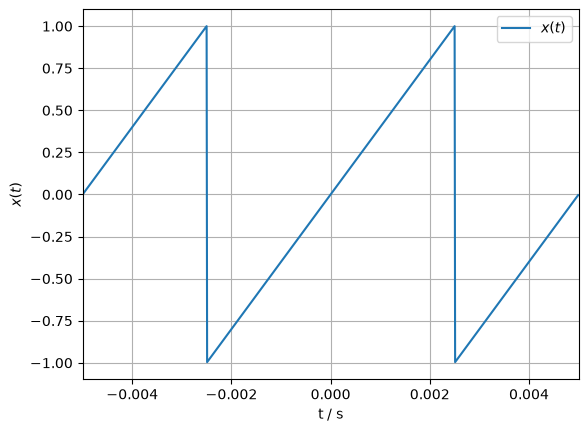

In [42]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import sounddevice as sd

t = np.arange(-5 * 10 ** -3, 5 * 10 ** -3, 0.01 * 10 ** -3)

x = -1 + (1 / 0.0025) * np.mod(t - 0.0025, 0.005)

fig, ax = plt.subplots()
ax.grid()

ax.set_xlim(-5 * 10 ** -3, 5 * 10 ** -3)

ax.set_xlabel('t / s')
ax.set_ylabel('$x(t)$')

ax.plot(t, x, label="$x(t)$")
ax.legend()

### b) 

The definition of exponential continuous-time Fourier series says that any $T_0$-periodic continuous-time signal $x(t)$ can be expressed in terms of its exponential continuous-time Fourier series:

$$
x(t) = \sum_{n=-\infty}^{\infty} c_ne^{jn\omega_0t}
$$

The signal $x(t) = -1 + \frac{1}{0.0025}\text{mod}(t - 0.0025, 0.005)$ is a $T_0$-periodic continuous-time signal. We can therefore approximate it as described above.

However, in a program we cannot have an infinite terms. Therefore we have to approximate the signal with a limited amount of terms. The figure generated by the code below shows that as $N$ grows larger, or approaches infinity, the approximated signals $x_N(t)$ approaches the real signal $x(t)$.

N=1: max |Im| = 0.00e+00
N=2: max |Im| = 2.78e-17
N=10: max |Im| = 2.08e-16
N=100: max |Im| = 2.98e-16


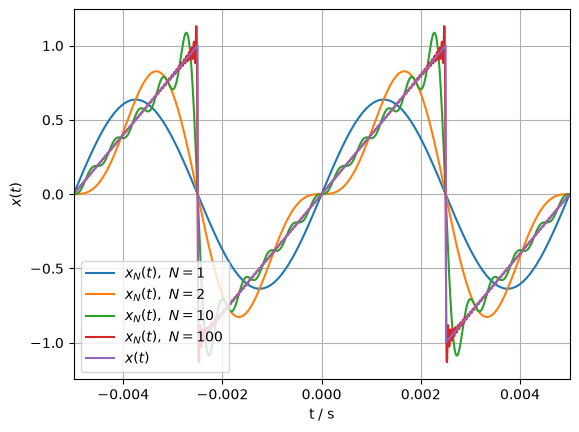

In [6]:
Ns = [1, 2, 10, 100]

T_0 = 5 * 10 ** -3
w_0 = 2 * np.pi / T_0

fig, ax = plt.subplots()
ax.grid()

ax.set_xlim(-5 * 10 ** -3, 5 * 10 ** -3)

ax.set_xlabel('t / s')
ax.set_ylabel('$x(t)$')

for N in Ns:
    x_N = 0
    for n in range(-N, N + 1):
        c_n = 0 if n == 0 else ((-1) ** n) * (1j) * (1 / (n * np.pi))
        term = c_n * np.exp(1j * n * w_0 * t)
        x_N += term

    print(f"N={N}: max |Im| = {np.max(np.abs(np.imag(x_N))):.2e}") # AI Generated
    x_N = np.real(x_N)
    ax.plot(t, x_N, label=f"$x_N(t), \\ N = {N}$")

ax.plot(t, x, label="$x(t)$")

ax.legend()

    

### c)

The signal $x(t)$ is $T_0$-periodic, where $T_0 = 5 \, \text{ms}$, which gives that $\omega_0 = \frac{2 \pi}{T_0} = \frac{2 \pi}{5 \cdot 10^{-3}} \approx 1257 \, \text{rad/s}$. A transform table therefore shows that the corresponding Fourier transform function is as follows:

$$
X(\omega) = 2 \pi \sum_{n}c_n \delta(\omega - n \omega_0) \iff X(\omega) = 2 \pi \sum_{n}c_n \delta(\omega - 1257 n)
$$



<StemContainer object of 3 artists>

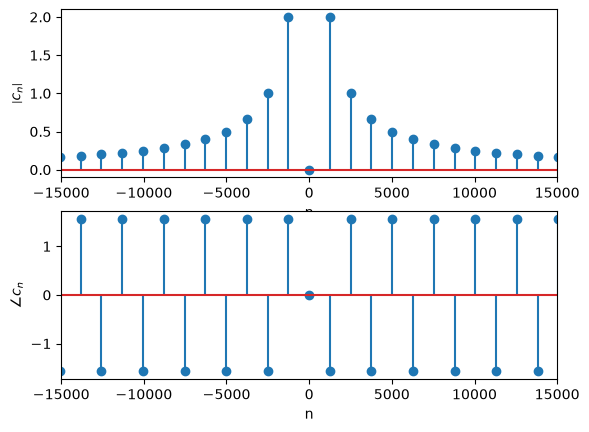

In [41]:
T_0 = 5 * 10 ** -3
w_0 = 2 * np.pi / T_0

M = 100

n = np.arange(-M, M + 1, 1)
wn = n * w_0

c_n = np.zeros(len(n), dtype=complex)
nz = n != 0
c_n[nz] = ((-1.0) ** n[nz]) * (1j) * (1 / (n[nz] * np.pi))

Xn = 2 * np.pi * c_n

fig, ax = plt.subplots(2, 1)

ax[0].set_xlim(-15 * 10 ** 3, 15 * 10 ** 3)
ax[0].set_xlabel('n')
ax[0].set_ylabel('$\\left| c_n \\right|$')

ax[1].set_xlim(-15 * 10 ** 3, 15 * 10 ** 3)
ax[1].set_xlabel('n')
ax[1].set_ylabel('$\\angle c_n$')

ax[0].stem(wn, np.abs(Xn))
ax[1].stem(wn, np.angle(Xn))